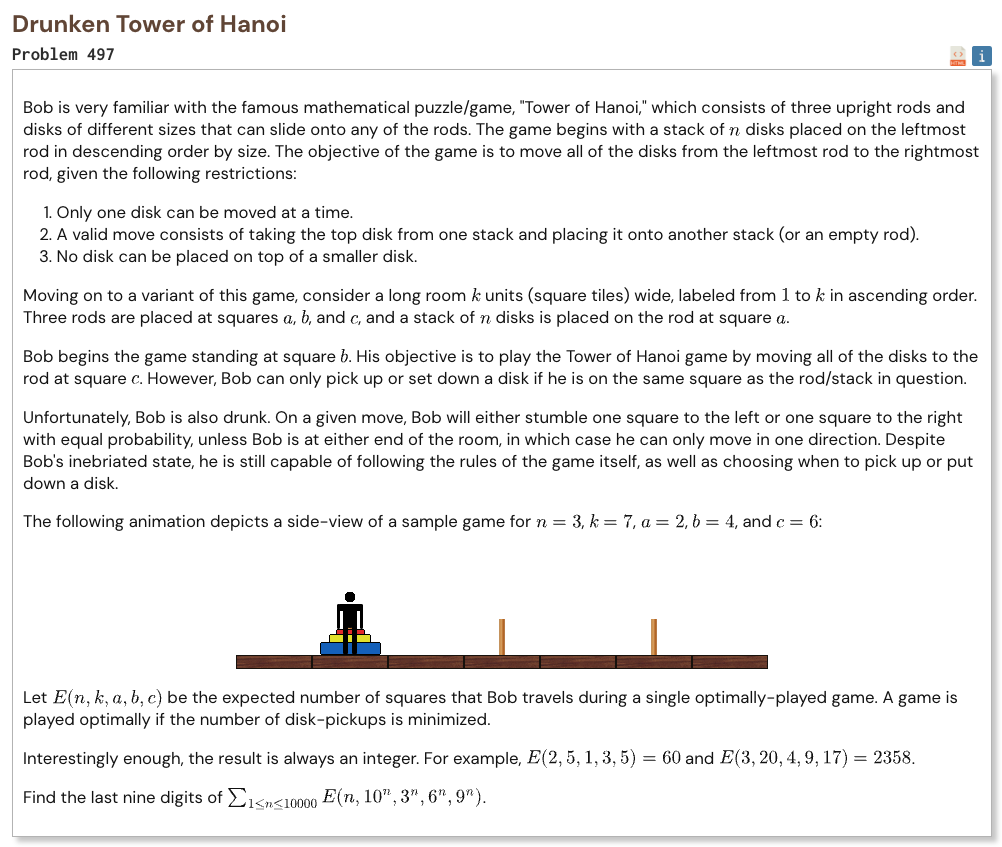

## Initial approach

- use the standard Tower of Hanoi recursion to count moves between each pair of rods
- keep six possible source target and helper arrangements as small states
- calculate the expected walking distance between two rod positions with the random walk hitting time
- include Bob's initial walk from the middle rod to the first rod
- update the Hanoi transition counts once for each disk number
- update the powers for the room size and three rod positions at the same time
- add every expected value modulo the last nine digits

In [1]:
%%time

from itertools import permutations

MOD = 10**9
N = 10_000

orientations = list(permutations(range(3), 3))
index = {
    orientation: i
    for i, orientation in enumerate(orientations)
}

def empty_matrix():
    return [
        [0] * 3
        for _ in range(3)
    ]

counts = []

for source, target, helper in orientations:
    matrix = empty_matrix()
    matrix[source][target] = 1
    counts.append(matrix)

def next_counts(current):
    result = []

    for source, target, helper in orientations:
        matrix = empty_matrix()

        first = current[index[(source, helper, target)]]
        second = current[index[(helper, target, source)]]

        for i in range(3):
            for j in range(3):
                matrix[i][j] = (
                    first[i][j] + second[i][j]
                ) % MOD

        matrix[helper][source] += 1
        matrix[source][target] += 1
        matrix[target][helper] += 1

        result.append(matrix)

    return result

def hitting_time(k, x, y):
    if x < y:
        return (
            (y - x)
            * (x + y - 2)
        ) % MOD

    if x > y:
        return (
            (x - y)
            * (2 * k - x - y)
        ) % MOD

    return 0

def expected_value(matrix, k, a, b, c):
    positions = [a, b, c]
    total = hitting_time(k, b, a)

    for i in range(3):
        for j in range(3):
            total += (
                matrix[i][j]
                * hitting_time(
                    k,
                    positions[i],
                    positions[j]
                )
            )

            total %= MOD

    return total

canonical = index[(0, 2, 1)]

p3 = 1
p6 = 1
p9 = 1
p10 = 1

result = 0

for n in range(1, N + 1):
    if n > 1:
        counts = next_counts(counts)

    p3 = p3 * 3 % MOD
    p6 = p6 * 6 % MOD
    p9 = p9 * 9 % MOD
    p10 = p10 * 10 % MOD

    result += expected_value(
        counts[canonical],
        p10,
        p3,
        p6,
        p9
    )

    result %= MOD

print("Result:", result)

Result: 122570186
CPU times: user 92.1 ms, sys: 1.57 ms, total: 93.7 ms
Wall time: 97.5 ms
